# ¿Qué relación existe entre la adopción del vehículo eléctrico, la infraestructura de recarga y las emisiones de CO₂ del transporte y los niveles predichos de NO₂ urbano?

Análisis exploratorio de 61 países. Cada dimensión utiliza su propia muestra y ventana temporal.

**Pregunta:** ¿Qué relación existe entre la adopción del vehículo eléctrico, la infraestructura de recarga y las emisiones de CO₂ del transporte y los niveles predichos de NO₂ urbano? Se contrasta si la adopción del vehículo eléctrico se asocia con una mayor reducción de las emisiones de CO₂ del transporte por habitante (H1), con niveles más bajos de NO₂ urbano predicho (H3) y si la infraestructura de recarga se asocia con una mayor penetración del vehículo eléctrico (H2).

**Hipótesis:**
- **H1 (principal):** Donde hay más coches eléctricos (cuota del parque 2023), el CO₂ del transporte por habitante baja más entre 2015 y 2023.
- **H2:** Los países con más puntos de recarga por habitante tienen más coches eléctricos en su parque (2024).
- **H3:** Donde hay más coches eléctricos, el NO₂ urbano predicho (media por área urbana, abril–noviembre de 2025) es menor.

Este notebook recorre el proceso completo: carga, valores nulos (pandas), limpieza, combinación de datasets, agrupaciones, análisis exploratorio con matplotlib, contraste de hipótesis y conclusiones.

## 0. Preparación

In [1]:
import sys, warnings
sys.path.append('utils')
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datos import *
from analisis import *
from graficos import estilo_analisis, mapa_coropletico, COLORES
estilo_analisis()
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)
%matplotlib inline

## 1. Carga de los datasets
Cada fuente se lee con su función de `utils/datos.py`. Todas tienen una clave común: `iso3` (país) y `anio`.

In [2]:
iea = cargar_iea()
wdi = pd.read_csv(RUTA_PROCESADOS / 'wdi_indicadores.csv')
afir = cargar_afir()
gni = cargar_gni()
fua = cargar_fua_2025()
resumen = pd.DataFrame({
    'fuente': ['IEA (coches eléctricos)', 'Banco Mundial (WDI)', 'AFIR (recarga UE)', 'Renta (GNI)', 'Calidad del aire 2025 (FUA)'],
    'filas': [len(iea), len(wdi), len(afir), len(gni), len(fua)],
    'paises': [iea.iso3.nunique(), wdi.iso3.nunique(), afir.iso3.nunique(), gni.iso3.nunique(), fua.iso3.nunique()]})
resumen

,fuente,filas,paises
0,IEA (coches eléctricos),780,61
1,Banco Mundial (WDI),4240,265
2,AFIR (recarga UE),188,27
3,Renta (GNI),229,229
4,Calidad del aire 2025 (FUA),61,61


In [3]:
iea.head()

,iso3,anio,parque_ev,ventas_ev,cuota_parque_pct,cuota_ventas_pct,puntos_recarga_publicos,pais
0,ARE,2012,350.0,200.0,0.014,0.065,NaN,United Arab Emirates
1,ARE,2013,940.0,140.0,0.033,0.037,NaN,United Arab Emirates
2,ARE,2014,1300.0,49.0,0.040,0.010,NaN,United Arab Emirates
3,ARE,2015,1900.0,85.0,0.050,0.015,NaN,United Arab Emirates
4,ARE,2016,2300.0,58.0,0.053,0.013,NaN,United Arab Emirates


In [4]:
wdi.head()

,iso3,anio,co2_transporte_mt,ghg_per_capita,pib_per_capita,pm25_medio_wdi,poblacion
0,ABW,2010,0.1793,5.193543,25429.218097,NaN,101838.0
1,ABW,2011,0.1042,3.322904,26093.054208,NaN,102591.0
2,ABW,2012,0.1319,3.896840,25444.733665,NaN,104110.0
3,ABW,2013,0.1464,4.168441,26680.141121,NaN,105675.0
4,ABW,2014,0.1602,4.399524,26773.822910,NaN,106807.0


In [5]:
afir.head()

,iso3,anio,afir_puntos_total,afir_puntos_dc
0,AUT,2020,8104,1230.0
1,AUT,2021,11739,1287.0
2,AUT,2022,17584,2333.0
3,AUT,2023,18636,3407.0
4,AUT,2024,30421,6208.0


In [6]:
fua.head()

,iso3,no2_2025,ciudades_no2,pm25_2025,ciudades_pm25,o3_2025,ciudades_o3,co_2025,ciudades_co
0,ARE,24.649719,6,58.245341,6,63.433017,6,536.190559,6
1,ARG,15.848756,63,12.330372,63,53.717561,63,430.811728,63
2,AUS,14.137576,19,7.114905,19,55.511201,19,337.005146,19
3,AUT,16.813324,6,12.598937,6,37.578537,6,372.005179,6
4,BEL,17.777257,10,12.031256,10,47.420115,10,259.012534,10


## 2. Valores nulos y ausentes (pandas)
Antes de limpiar, medimos cuántos valores faltan en cada columna del dataset de coches eléctricos.

In [7]:
nulos = iea.isna().agg(['sum']).T.rename(columns={'sum': 'nulos'})
nulos['porcentaje'] = (nulos['nulos'] / len(iea) * 100).round(1)
nulos.sort_values('porcentaje', ascending=False)

,nulos,porcentaje
puntos_recarga_publicos,338,43.3
parque_ev,160,20.5
cuota_parque_pct,160,20.5
cuota_ventas_pct,18,2.3
ventas_ev,12,1.5
anio,0,0.0
iso3,0,0.0
pais,0,0.0


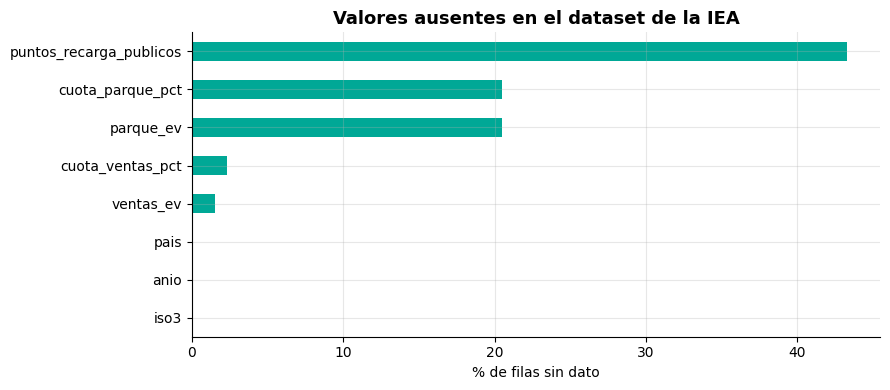

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
nulos.sort_values('porcentaje').plot.barh(y='porcentaje', ax=ax, legend=False, color=COLORES['electrico'])
ax.set_xlabel('% de filas sin dato')
ax.set_title('Valores ausentes en el dataset de la IEA')
plt.tight_layout(); plt.show()

## 3. Limpieza
- **Nombres de país:** cada fuente los escribe distinto; los unimos por código ISO3 y descartamos agregados regionales (`World`, `Europe`, `European Union`…).
- **Solo datos históricos:** la IEA incluye proyecciones; las excluimos.
- **Duplicados:** comprobamos que no haya dos filas para el mismo país y año.
- **Ausencias:** no rellenamos con ceros. Cada contraste usa solo los países con datos completos.

In [9]:
hist = iea.copy()
print('Duplicados país-año:', hist.duplicated(['iso3', 'anio']).sum())
print('Países sin código ISO3 tras el mapeo:', iea['iso3'].isna().sum())
print('Rango de la cuota del parque (%):', iea['cuota_parque_pct'].min(), '-', iea['cuota_parque_pct'].max())
print('Rango de años:', iea['anio'].min(), '-', iea['anio'].max())
iea.describe().round(2)

Duplicados país-año: 0
Países sin código ISO3 tras el mapeo: 0
Rango de la cuota del parque (%): 2.1e-05 - 36.0
Rango de años: 2010 - 2025


,anio,parque_ev,ventas_ev,cuota_parque_pct,cuota_ventas_pct,puntos_recarga_publicos
count,780.00,620.00,768.00,620.00,762.00,442.00
mean,2018.55,386208.79,101824.63,1.60,8.00,52188.77
std,4.34,2477028.47,734559.53,4.01,14.82,307570.76
min,2010.00,2.00,1.00,0.00,0.00,2.00
25%,2015.00,1300.00,350.00,0.02,0.15,911.75
50%,2019.00,12000.00,3450.00,0.16,1.55,4080.00
75%,2022.00,130000.00,29000.00,1.10,8.80,19400.00
max,2025.00,44000000.00,13000000.00,36.00,97.00,4680000.00


## 4. Combinación de datasets
Unimos IEA, Banco Mundial, AFIR y renta en un panel país-año y añadimos variables derivadas.

In [10]:
p = construir_panel()
print('Filas del panel:', len(p), '| países:', p['iso3'].nunique(), '| años:', p['anio'].min(), '-', p['anio'].max())
p[['iso3', 'pais', 'anio', 'cuota_parque_pct', 'co2_transporte_pc', 'puntos_por_1000_hab', 'pib_per_capita', 'grupo_renta']].head(8)

Filas del panel: 976 | países: 61 | años: 2010 - 2025


,iso3,pais,anio,cuota_parque_pct,co2_transporte_pc,puntos_por_1000_hab,pib_per_capita,grupo_renta
0,ARE,United Arab Emirates,2010,NaN,4.375052,NaN,42328.846682,Renta muy alta
1,ARE,United Arab Emirates,2011,NaN,4.234575,NaN,43687.791942,Renta muy alta
2,ARE,United Arab Emirates,2012,0.014,4.161783,NaN,43958.577967,Renta muy alta
3,ARE,United Arab Emirates,2013,0.033,4.506871,NaN,44312.632046,Renta muy alta
4,ARE,United Arab Emirates,2014,0.040,4.414364,NaN,44257.665209,Renta muy alta
5,ARE,United Arab Emirates,2015,0.050,3.630822,NaN,44910.345886,Renta muy alta
6,ARE,United Arab Emirates,2016,0.053,3.875695,NaN,45168.495597,Renta muy alta
7,ARE,United Arab Emirates,2017,0.052,4.083246,NaN,43293.020236,Renta muy alta


In [11]:
p.isna().sum()[p.isna().sum() > 0].to_frame('nulos_en_panel')

,nulos_en_panel
parque_ev,356
ventas_ev,208
cuota_parque_pct,356
cuota_ventas_pct,214
puntos_recarga_publicos,534
co2_transporte_mt,61
ghg_per_capita,61
pib_per_capita,1
pm25_medio_wdi,122
afir_puntos_total,821


## 5. Agrupaciones y numpy
Resumimos por nivel de renta y comparamos la adopción y la recarga entre grupos.

In [12]:
tabla_grupos = (p[p['anio'] == ANIO_CORTE]
                .groupby('grupo_renta', observed=True)
                .agg(paises=('iso3', 'nunique'),
                     cuota_media=('cuota_parque_pct', 'mean'),
                     cuota_mediana=('cuota_parque_pct', 'median'),
                     puntos_por_1000_mediana=('puntos_por_1000_hab', 'median')))
tabla_grupos.round(2)

,paises,cuota_media,cuota_mediana,puntos_por_1000_mediana
grupo_renta,,,,
Renta media-baja,20,1.38,0.59,0.06
Renta alta,21,2.11,1.40,0.68
Renta muy alta,20,9.05,5.90,1.81


In [13]:
# numpy: transformación logarítmica de la renta y resumen por percentiles
log_pib = np.log(p.loc[p['anio'] == ANIO_CORTE, 'pib_per_capita'].dropna())
print('PIB per cápita (log) - percentiles 10/50/90:', np.percentile(log_pib, [10, 50, 90]).round(2))

PIB per cápita (log) - percentiles 10/50/90: [ 8.38  9.91 11.03]


## 6. Análisis exploratorio con matplotlib

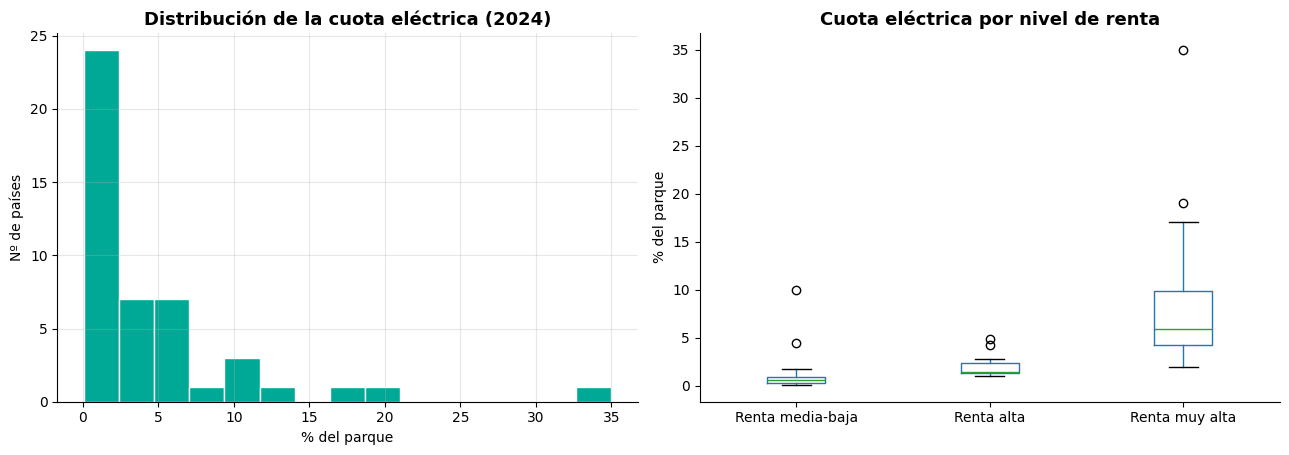

In [14]:
q24 = p[p['anio'] == ANIO_CORTE].dropna(subset=['cuota_parque_pct'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].hist(q24['cuota_parque_pct'], bins=15, color=COLORES['electrico'], edgecolor='white')
axes[0].set_title('Distribución de la cuota eléctrica (2024)')
axes[0].set_xlabel('% del parque'); axes[0].set_ylabel('Nº de países')
q24.boxplot(column='cuota_parque_pct', by='grupo_renta', ax=axes[1], grid=False)
axes[1].set_title('Cuota eléctrica por nivel de renta')
axes[1].set_xlabel(''); axes[1].set_ylabel('% del parque'); plt.suptitle('')
plt.tight_layout(); plt.show()

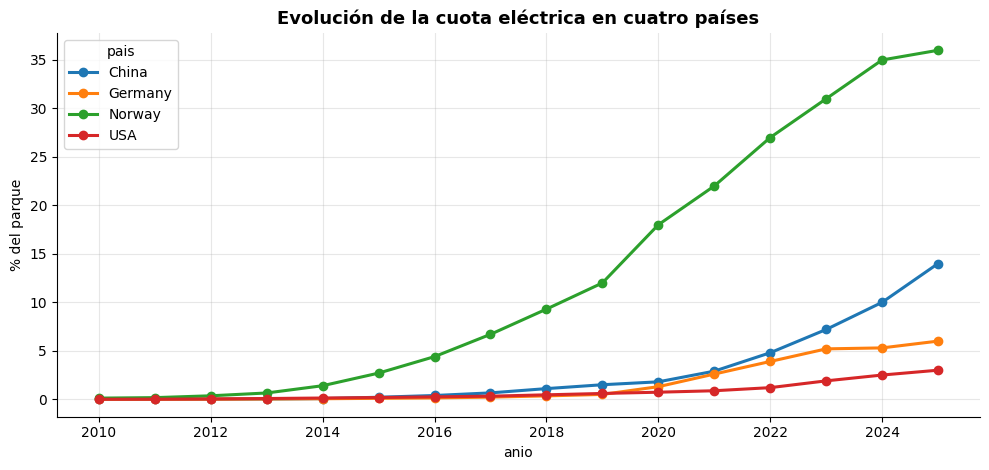

In [15]:
evol = p[p['pais'].isin(['Norway', 'China', 'USA', 'Germany'])].pivot_table(index='anio', columns='pais', values='cuota_parque_pct')
fig, ax = plt.subplots(figsize=(10, 4.8))
evol.plot(ax=ax, marker='o', linewidth=2.2)
ax.set_title('Evolución de la cuota eléctrica en cuatro países'); ax.set_ylabel('% del parque')
plt.tight_layout(); plt.show()

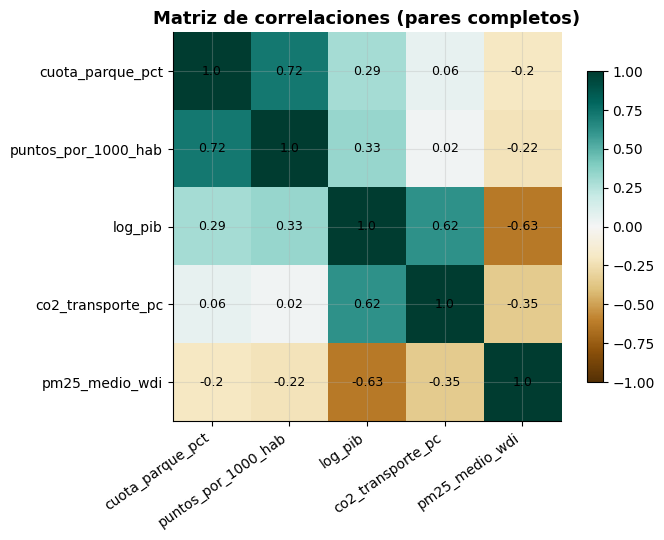

In [16]:
corr_vars = ['cuota_parque_pct', 'puntos_por_1000_hab', 'log_pib', 'co2_transporte_pc', 'pm25_medio_wdi']
corr = p[corr_vars].corr().round(2)
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap='BrBG', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_vars))); ax.set_xticklabels(corr_vars, rotation=35, ha='right')
ax.set_yticks(range(len(corr_vars))); ax.set_yticklabels(corr_vars)
for i in range(len(corr_vars)):
    for j in range(len(corr_vars)):
        ax.text(j, i, corr.iloc[i, j], ha='center', va='center', fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title('Matriz de correlaciones (pares completos)')
plt.tight_layout(); plt.show()

## 7. Contraste de hipótesis

In [17]:
d1, m1_simple, m1_control = h1_emisiones_transporte(p)
print(f'H1 · n = {len(d1)} países')
pd.DataFrame({'simple': m1_simple.params, 'p_simple': m1_simple.pvalues,
              'con_renta': m1_control.params, 'p_con_renta': m1_control.pvalues}).round(4)

H1 · n = 46 países


,simple,p_simple,con_renta,p_con_renta
Intercept,6.8464,0.1228,109.6807,0.0022
cuota_2023,-1.4715,0.1058,-0.3678,0.2901
log_pib_2023,NaN,NaN,-10.8060,0.0019


In [18]:
h2 = h2_infraestructura(p)
print(f"H2 · n = {len(h2['datos'])} | r = {h2['r']:.3f} | IC95 bootstrap = [{h2['ic'][0]:.3f}, {h2['ic'][1]:.3f}]")
print(f"R² recarga = {h2['m_pts'].rsquared:.3f} | R² renta = {h2['m_renta'].rsquared:.3f}")
pd.DataFrame({'coef': h2['m_ambas'].params, 'p': h2['m_ambas'].pvalues}).round(4)

H2 · n = 43 | r = 0.662 | IC95 bootstrap = [0.509, 0.910]
R² recarga = 0.439 | R² renta = 0.274


,coef,p
Intercept,-14.7850,0.0428
puntos_por_1000_hab,1.3834,0.0574
log_pib,1.7260,0.0259


In [19]:
ue, r_ue = h2_ue(p, cargar_afir())
print(f'H2 en la UE · n = {len(ue)} países | r(ventas, puntos por 1.000 hab) = {r_ue:.3f}')
ue.sort_values('cuota_ventas_pct', ascending=False).round(2).head(10)

H2 en la UE · n = 26 países | r(ventas, puntos por 1.000 hab) = 0.828


,pais,cuota_ventas_pct,poblacion,puntos_afir,puntos_por_1000_hab
iso3,,,,,
SWE,Sweden,58.0,10569709.0,53778,5.09
DNK,Denmark,56.0,5976992.0,35869,6.00
FIN,Finland,50.0,5619911.0,16726,2.98
NLD,Netherlands,48.0,17993485.0,183000,10.17
BEL,Belgium,43.0,11858610.0,76819,6.48
LUX,Luxembourg,36.0,677012.0,2651,3.92
PRT,Portugal,33.0,10694681.0,12119,1.13
IRL,Ireland,25.0,5395790.0,3588,0.66
FRA,France,24.0,68551653.0,155931,2.27


In [20]:
q3, r3, m3s, m3c = h3_calidad_aire(p, fua)
print(f'H3 · n = {len(q3)} | r = {r3:.3f}')
pd.DataFrame({'simple': m3s.params, 'p_simple': m3s.pvalues,
              'con_renta': m3c.params, 'p_con_renta': m3c.pvalues}).round(4)

H3 · n = 46 | r = -0.278


,simple,p_simple,con_renta,p_con_renta
Intercept,21.3035,0.0000,35.1959,0.0063
cuota_parque_pct,-0.3186,0.0322,-0.1894,0.1130
log_pib,NaN,NaN,-1.4642,0.2627


**Variable NO₂.** `no2_pred` es un valor predicho, obtenido a partir de predicciones diarias por celda para el periodo abril-noviembre de 2025. La unidad de medida no está documentada en el archivo de origen, por lo que no se atribuye a ella ninguna unidad.

**Agregación.** Para cada área urbana funcional (FUA) se calcula la media de todas las observaciones celda-día disponibles (`suma / recuento`). Después, el valor del país es la media de sus áreas urbanas, sin ponderar por población. Un control (`outputs/tablas/control_agregacion_no2.csv`) compara este método con una media diaria por FUA: la diferencia mediana por FUA es 0,003 y no altera la conclusión de H3 (p = 0,032 en ambos casos).

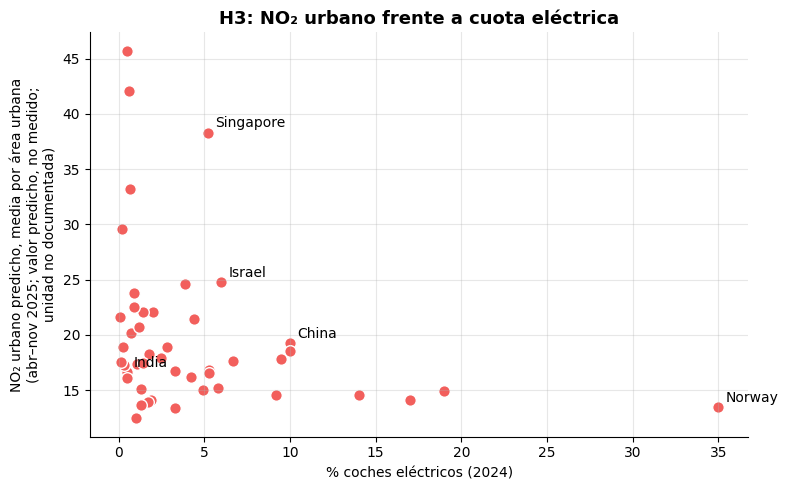

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(q3['cuota_parque_pct'], q3['no2_2025'], s=70, color=COLORES['emision'], edgecolor='white')
for iso, fila in q3.iterrows():
    if fila['pais'] in ['Norway', 'Singapore', 'Israel', 'China', 'India']:
        ax.annotate(fila['pais'], (fila['cuota_parque_pct'], fila['no2_2025']), xytext=(5, 4), textcoords='offset points')
ax.set_xlabel('% coches eléctricos (2024)'); ax.set_ylabel('NO₂ urbano predicho, media por área urbana\n(abr–nov 2025; valor predicho, no medido;\nunidad no documentada)')
ax.set_title('H3: NO₂ urbano frente a cuota eléctrica'); plt.tight_layout(); plt.show()

In [22]:
# Ajuste por comparaciones múltiples (leído de los resultados verificados)
ajustes = pd.read_csv('outputs/tablas/contrastes_ajustados.csv')
principal = ajustes[ajustes['familia'] == 'P_principal']
tabla_holm = principal[['contraste', 'p_nominal_HC3', 'p_holm', 'p_bh']].round(3)
# Holm: H1 y H2 con tres decimales; H3 con cuatro (0,0645). Solo cambia la presentación.
tabla_holm['p_holm'] = [f'{v:.4f}' if c == 'H3' else f'{v:.3f}'
                        for c, v in zip(principal['contraste'], principal['p_holm'])]
tabla_holm


,contraste,p_nominal_HC3,p_holm,p_bh
0,H1,0.106,0.106,0.106
1,H2,0.021,0.062,0.048
2,H3,0.032,0.0645,0.048


## 8. Mapas
El mapa interactivo (folium) con cifras por país está en `outputs/mapa_interactivo_adopcion_2024.html`. Aquí, la versión estática con matplotlib.

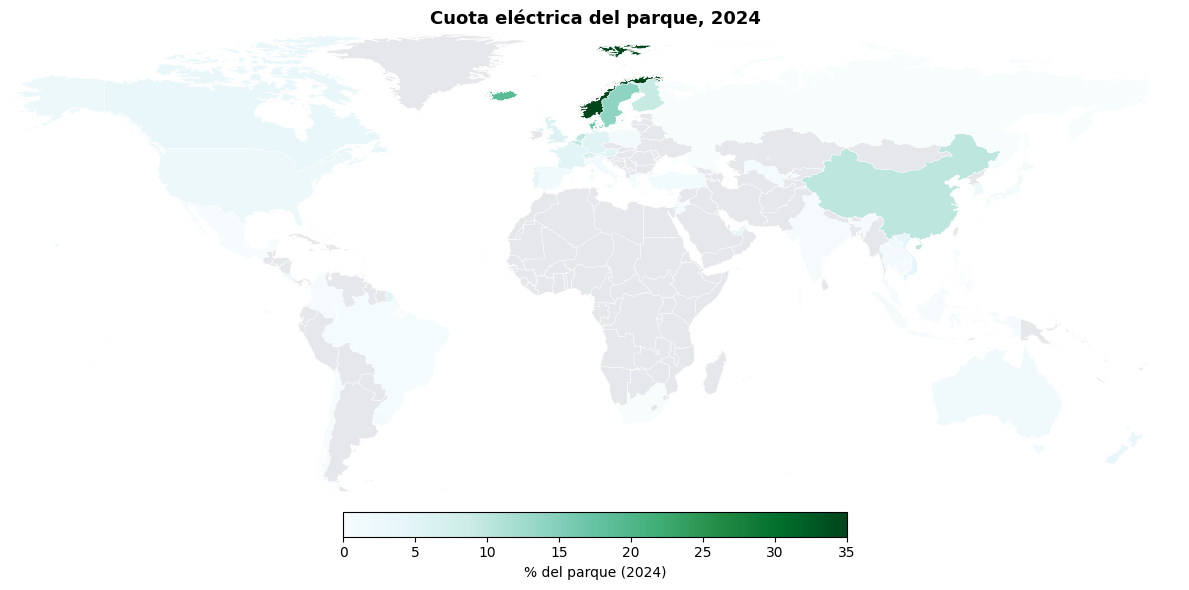

In [23]:
fig, ax = plt.subplots(figsize=(12, 6))
cuota24 = p[p['anio'] == ANIO_CORTE].set_index('iso3')['cuota_parque_pct']
sm = mapa_coropletico(ax, cuota24, cmap='BuGn', vmin=0, vmax=35)
fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.05, pad=0.02, label='% del parque (2024)')
ax.set_title('Cuota eléctrica del parque, 2024'); plt.tight_layout(); plt.show()

## 9. Conclusiones

**Estimador principal:** HC3. Los errores clásicos y HC1 solo se muestran como sensibilidad.

**Ajuste por comparaciones múltiples.** Holm es el ajuste complementario principal para las tres hipótesis principales. Tras Holm, ninguna conserva la significación al 5 %:

| Hipótesis | p HC3 original | p Holm |
|---|---:|---:|
| H1 | 0,106 | 0,106 |
| H2 | 0,021 | 0,062 |
| H3 | 0,032 | 0,0645 |

BH (H2 y H3: 0,048) se presenta solo como sensibilidad; no sustituye a Holm.

**Resultados principales**

1. **H1 (sin evidencia de relación lineal):** sin controles, la pendiente no es significativa (p = 0,106). La correlación de Spearman sí es negativa y significativa (ρ ≈ −0,45; p = 0,002): la asociación es monótona. Con renta, la renta es significativa (p = 0,002) y la cuota no (p = 0,290).
2. **H2 (asociación positiva y fuerte):** r = 0,66 (IC 95 %: 0,51 a 0,91; 43 países). Sin controles, p = 0,021 (Holm: 0,062). Con los tres controles, p = 0,034, pero la significación depende de cuatro países: sin Bélgica, Islandia, Corea del Sur o Países Bajos, p supera 0,05. Con la renta sola, p = 0,057. Es asociación, no causa.
3. **H3 (asociación negativa débil y condicionada):** sin controles, r = −0,28 y p = 0,032 (Holm: 0,0645). Esa significación desaparece si se excluyen Dinamarca (p = 0,0537) o Islandia (p = 0,0854); sin Singapur, p = 0,0505, queda en el límite. Con renta, p = 0,113; con renta, urbanización y densidad, p = 0,724.

**Sensibilidades (no sustituyen a los resultados principales)**

- **H1 en 2015–2019:** la pendiente sí es significativa con HC3 (p = 0,004; Holm dentro de su familia: 0,018). No es un resultado principal: el periodo se eligió después de ver los datos.
- **Sin Noruega:** Noruega se mantiene en el análisis principal. Sin ella, la asociación de H3 se refuerza (p = 0,008).
- **BH:** ajuste alternativo con menor exigencia, mostrado solo como sensibilidad.

**Análisis exploratorios:** España frente a Europa y la prima de precio. No son contrastes de hipótesis.

**Limitaciones:** muestras de 43 a 46 países según el contraste (de 61 en el panel); NO₂ de abril a noviembre de 2025, sin invierno; cuota de 2024 frente a NO₂ de 2025; `no2_pred` es un valor predicho con unidad no documentada; la unidad de análisis del NO₂ es el área urbana funcional (FUA), y el valor del país es la media de sus FUA sin ponderar por población. Los resultados sensibles a un solo país o a un periodo no deben citarse como firmes.

El detalle por estimador está en `outputs/tablas/comparacion_estimadores.csv`, la influencia en `outputs/tablas/influencia_loo.csv`, los ajustes en `outputs/tablas/contrastes_ajustados.csv` y la robustez en la memoria (secciones 6 y 7).

In [24]:
outputs = RAIZ_SALIDA = Path('outputs/tablas'); outputs.mkdir(parents=True, exist_ok=True)
tabla_grupos.to_csv(outputs / 'resumen_por_renta_2024.csv')
d1.to_csv(outputs / 'h1_cambio_co2_transporte.csv')
h2['datos'].to_csv(outputs / 'h2_recarga_adopcion.csv')
q3.to_csv(outputs / 'h3_no2_adopcion.csv')
print('Tablas exportadas en', outputs)

Tablas exportadas en outputs/tablas
